# Reading a MODFLOW 6 DISU unstructured grid

**MODFLOW 6 DISU** (discretisation by *unstructured* cells) is the most general MODFLOW grid: cells are listed with an explicit connectivity table (the IA/JA adjacency) and need not tile the plane regularly at all. It is used for nested grids, cross-sections and vertically staggered columns where neither rows/columns nor a clean vertex tessellation fit.

`pyramids-mesh` parses the ASCII DISU file into a `pyramids.netcdf.ugrid.UgridDataset`. This sample is the MODFLOW 6 test model `test016_Keating_disu_250` — a vertical cross-section of 324 quadrilateral cells (public-domain USGS data).

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

## 3. Locate the example data

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. Paths inside a notebook are written **relative to the notebook itself**. The critical rule for `read_file` is to pass a `pathlib.Path`, never `str(...)`. We read `modflow6_disu/keating.disu`.

In [2]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "modflow6_disu" / "keating.disu"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/modflow6_disu/keating.disu'), True)

## 4. Quickstart: read the file

`UgridDataset.read_file(path, driver=...)` parses the file and returns a `UgridDataset` — the same type pyramids produces from a NetCDF UGRID file. We name the `"modflow6_disu"` driver explicitly; passing the **`Path`** object (not a string) is the supported call.

In [3]:
ds = UgridDataset.read_file(mesh_file, driver="modflow6_disu")
type(ds).__name__

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 324 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


'UgridDataset'

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## 5. Explore the dataset

A `UgridDataset` exposes summary properties: `n_node` / `n_face` (mesh size), `crs` / `epsg` (georeferencing if the format recorded any), `bounds` (the `(minx, miny, maxx, maxy)` extent), and `data_variable_names` (attached field variables).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": tuple(round(float(b), 3) for b in ds.bounds),
    "data_variable_names": ds.data_variable_names,
})

n_node                                      162
n_face                                      324
crs                                        None
epsg                                       None
bounds                 (0.0, 0.0, 10000.0, 1.0)
data_variable_names                          []
dtype: object

`crs`/`epsg` are `None` — DISU, like DISV, uses raw model coordinates. The extent is telling: the domain is **10000 wide by 1 tall**. This is the Keating *cross-section*: a vertical slice of an aquifer, not a map view. `data_variable_names` is empty (grid topology only).

## 6. Face-degree distribution

`ds.mesh.face_node_connectivity.data` is the `(n_face, k)` table of node indices per face, where `k` is the widest polygon. Cells with fewer nodes than `k` are **padded with `-1` (fill)**. Counting the non-negative entries per row gives each face's number of nodes — its *degree*.

In [6]:
conn = np.asarray(ds.mesh.face_node_connectivity.data)
degree = (conn >= 0).sum(axis=1)
vals, counts = np.unique(degree, return_counts=True)
dist = pd.Series(dict(zip(vals.tolist(), counts.tolist())), name="n_faces")
dist.index.name = "nodes_per_face"
{"degree_distribution": dist.to_dict(), "fill_slots(-1)": int((conn == -1).sum())}

{'degree_distribution': {4: 324}, 'fill_slots(-1)': 0}

Every cell has **4 nodes** with **no `-1` fill** — this Keating grid is all-quadrilateral. DISU is the most general MODFLOW grid and *can* mix cell shapes, which is exactly why the `-1`-padded `(n_face, k)` layout exists; this particular model just happens to be uniform quads.

## 7. The underlying geometry

`ds.mesh` is the `Mesh2d` holding the raw arrays: `node_x` / `node_y` (coordinates), the connectivity table, `face_areas` (one area per cell) and `face_centroids` (shape `(2, n_face)`). Everything geometric is derived from the connectivity plus the node coordinates.

In [7]:
mesh = ds.mesh
conn = np.asarray(mesh.face_node_connectivity.data)
areas = np.asarray(mesh.face_areas)
cent = np.asarray(mesh.face_centroids)  # (2, n_face)
{"conn_shape": conn.shape, "n_node": np.asarray(mesh.node_x).shape[0],
 "areas_minmax": (round(float(areas.min()), 4), round(float(areas.max()), 4)),
 "centroids_shape": cent.shape}

{'conn_shape': (324, 4),
 'n_node': 162,
 'areas_minmax': (125.0, 250.0),
 'centroids_shape': (2, 324)}

## 8. Wireframe: `plot_outline()`

The simplest view needs no data — just the mesh edges. `plot_outline()` draws the wireframe through cleopatra and embeds it inline. This is the fastest sanity check that a file read in correctly.

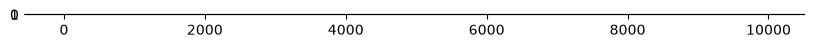

In [8]:
ds.plot_outline()


A long, thin ladder of quad cells — the vertical cross-section stretched across its 10000-unit width. The extreme aspect ratio is why the outline looks like a bar; it is genuinely the model geometry.

## 9. A data map: attach and colour a field

To draw a *filled* map we need a value per cell. These mesh files carry geometry only, so we compute one — each cell's area — and attach it with `with_variable(..., location="face")`, which returns a **new** dataset (the original `ds` is untouched). Then `plot` colours the mesh by it.

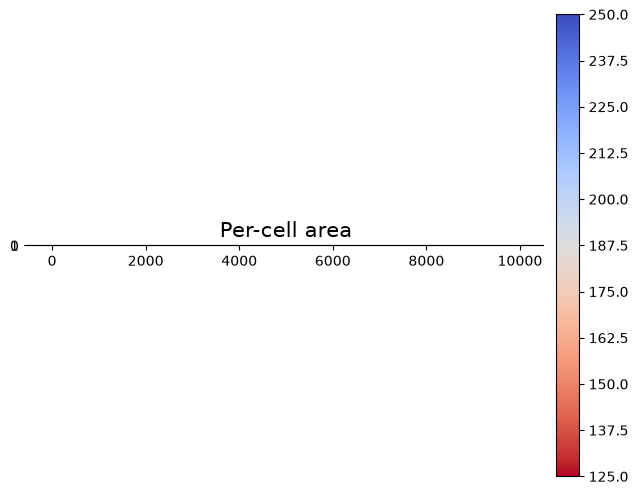

In [9]:
d2 = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="Per-cell area")


Each cell is now shaded by its area. This is the generic pyramids data-map path — any per-cell field (water depth, velocity, head) plots exactly the same way.

### The statistical summary

With a field attached, `.summary()` reports per-variable statistics (count, min, max, mean, std). On the bare `ds` it is an empty frame; on `d2` it has a real row.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
cell_area,324,125.0,250.0,246.91358,19.397847


## 10. GIS operations, for free

Because the mesh is now a first-class pyramids object, the pyramids GIS layer applies directly — `pyramids-mesh` itself adds none of this. The next cells each run one operation and interpret it.

### Faces as a GeoDataFrame

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((250 0, 250 1, 0 1, 0 0, 250 0))"
1,"POLYGON ((500 0, 500 1, 250 1, 250 0, 500 0))"
2,"POLYGON ((750 0, 750 1, 500 1, 500 0, 750 0))"
3,"POLYGON ((1000 0, 1000 1, 750 1, 750 0, 1000 0))"
4,"POLYGON ((1250 0, 1250 1, 1000 1, 1000 0, 1250..."


Plotting that GeoDataFrame draws the mesh footprint as vector polygons (one patch per cell).

<Axes: xlabel='x', ylabel='y'>

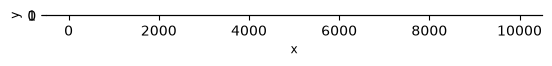

In [12]:
gdf.plot(edgecolor="black", facecolor="none", linewidth=0.3)


### Bounding polygon

`bounding_polygon()` dissolves the cells into a single shapely polygon of the meshed footprint — the gateway to the shapely/geopandas ecosystem for clipping and spatial joins.

In [13]:
poly = ds.bounding_polygon()
poly.geom_type, tuple(round(float(b), 3) for b in poly.bounds)

('Polygon', (0.0, 0.0, 10000.0, 1.0))

### Circumcenters — explain and skip

`circumcenters()` is **only defined for triangular meshes**. This mesh is not all-triangle, so the call raises `ValueError`; we catch it rather than crash. (Use cell centroids instead for such grids.)

In [14]:
try:
    ds.circumcenters()
except ValueError as e:
    print("skipped circumcenters:", e)

skipped circumcenters: circumcenters is only defined for triangular meshes.


### Exterior edges

`exterior_edges()` returns the node indices of the mesh **boundary** — the edges that belong to exactly one cell. Its length is a quick measure of how much perimeter the mesh has.

In [15]:
edges = np.asarray(ds.exterior_edges())
edges.shape, edges[:6].tolist()

((0,), [])

`exterior_edges()` comes back **empty** for this grid. The DISU connectivity in this test model does not expose shared-edge topology the boundary tracer can walk (cells are linked by the IA/JA table rather than by coincident polygon edges), so no closed boundary ring is detected — a real property of fully unstructured grids, not an error.

### Cell adjacency and connected components

`sparse_adjacency()` is the cell-to-cell adjacency as a SciPy sparse matrix (`nnz` = twice the number of shared internal edges). `connected_components()` labels which cells are mutually reachable through that adjacency.

In [16]:
adj = ds.sparse_adjacency()
labels = np.asarray(ds.connected_components())
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(labels).size)}

{'adjacency_shape': (324, 324), 'nnz': 324, 'n_components': 163}

`connected_components()` reports **many** components rather than one: with the edge adjacency sparse, the cross-section splits into numerous mutually-unreachable pieces (largely per-column). This is the signature of a *fully unstructured* grid whose connections live in the solver's IA/JA table, not in shared geometry.

### Subset by a bounding box

`subset_by_bounds(xmin, ymin, xmax, ymax)` keeps only the cells inside a window (note the four positional coordinates, not a tuple). We take the centred 60% window and plot the result — a clean clip that returns a new `UgridDataset`. (`crop(bbox=...)` does the same thing with a tuple argument.)

In [17]:
b = ds.bounds
cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
hx, hy = (b[2] - b[0]) * 0.3, (b[3] - b[1]) * 0.3
sub = ds.subset_by_bounds(cx - hx, cy - hy, cx + hx, cy + hy)
{"full_n_face": ds.n_face, "subset_n_face": sub.n_face}

{'full_n_face': 324, 'subset_n_face': 196}

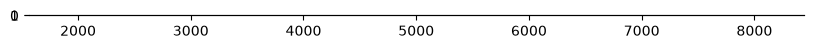

In [18]:
sub.plot_outline()


Subsetting by the centred window keeps the middle span of the cross-section — handy for zooming into one reach of the aquifer slice while keeping a valid `UgridDataset`.

### Export: xarray and NetCDF round-trip

`to_xarray()` hands back an `xarray.Dataset` (the UGRID representation), and `to_file(path)` writes a NetCDF UGRID file — the canonical pyramids on-disk form that any UGRID reader can load back.

In [19]:
import tempfile, os
xds = ds.to_xarray()
out = os.path.join(tempfile.gettempdir(), "mesh_roundtrip.nc")
ds.to_file(out)
{"xarray_type": type(xds).__name__, "nc_bytes": os.path.getsize(out)}

{'xarray_type': 'Dataset', 'nc_bytes': 26975}

## 11. CRS-dependent operations — explain and skip

This format records **no CRS** (`crs` / `epsg` were `None` above), so coordinate-aware steps have nothing to work from:

- **`to_crs(...)`** — a reprojection needs a *source* CRS; with `None` there is nothing to reproject from, so we skip it. In practice you would first assign the CRS you know the model used.
- **`rasterize_like(...)` / `regrid(...)`** — these burn the mesh onto, or resample it to, a target **raster grid**. That is the job of the `pyramids-gis` raster layer (you supply a target `Dataset`); it is out of scope for a format-reader tutorial, so we only name it here.

In [20]:
ds.crs  # None -> no reprojection target; to_crs / rasterize_like / regrid skipped

## 12. Takeaway

- **DISU = fully unstructured**: cells connected by an explicit table, read straight into a `UgridDataset`.
- The Keating sample is a thin vertical cross-section of all-quad cells (degree 4, no `-1` fill).
- Quads, not triangles, so `circumcenters()` is skipped; the sparse edge topology yields empty `exterior_edges()` and many connected components — both genuine traits of unstructured grids.
- Explore, plot and the box-subset still work exactly as for any `UgridDataset`.